# Continuation: independent multi-galaxy verification

The existing 26-galaxy study is preserved. This supplement independently recomputes its main statistics and tests exclusion of the four zero-projected-dust objects. Exclusion is descriptive sensitivity, not a correction for unknown source-product systematics. The complete primary notebook and 22-band tables remain one directory above.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image, Markdown
HERE = Path.cwd()
STUDY = HERE.parent
sys.path.insert(0, str(HERE))
import verify_existing_study as audit
receipt = json.loads((HERE/'verification_receipt.json').read_text())
display(receipt)

{'executed_UTC': '2026-10-27T01:17:55.461339+00:00',
 'executable': '/home/bahareh/miniforge3/envs/phd/bin/python',
 'primary_results': 'Existing frozen protocol retained',
 'new_sensitivity': 'Exclude zero-projected-dust objects, descriptively only; not a physical-null correction',
 'study_files_hash_checked': 795,
 'previous_result_files_unchanged': 289,
 'fresh_archive_hashes': 26,
 'independent_galaxy_gain_max_difference': 9.974659986866641e-17,
 'observing_replay_galaxies': 5,
 'independent_native_R50_checks': 20,
 'raw_FITS_spotchecks': 2,
 'original_executed_notebook_cells': 12,
 'original_embedded_figures': 11,
 'status': 'Numerical reproduction PASS; source-product physical-null calibration UNRESOLVED'}

## Independent native paired calculation

Subtract matched absolute morphologies, average the five views within each galaxy, then bootstrap independent galaxies. R50 is conditioned on the fixed R<12-kpc aperture. Intervals describe selected-sample variation and exclude instrumental/source-model systematics.

In [2]:
native, nonzero = audit.verify_native()
display(native)

,scope,band,n_galaxies,median_delta_R50_kpc,CI_low,CI_high,n_positive,n_negative,minimum,maximum
0,all_26,LSST_g,26,0.400304,0.170393,0.545911,24,1,-1.066361,1.685644
1,all_26,2MASS_Ks,26,0.123863,0.082745,0.170211,25,1,-0.058454,0.496062
2,nonzero_projected_dust_22,LSST_g,22,0.500741,0.358967,0.589012,21,1,-1.066361,1.685644
3,nonzero_projected_dust_22,2MASS_Ks,22,0.138764,0.109380,0.181987,21,1,-0.058454,0.496062


## Independently reconstructed observing errors

Use independent clear-versus-dusty observation noise, paired between strategies. Retain jointly valid draws, require at least six per view, then average draws, views and galaxies in that order. Positive gain means seeing absolute error minus GLAO absolute error. This is fixed-rest-band degradation, not exact observer-frame forecasting.

In [3]:
accuracy, difference = audit.verify_accuracy(nonzero)
print('Maximum difference from recorded per-galaxy gains:', difference)
display(accuracy[(accuracy.band=='2MASS_Ks') & accuracy.metric.isin(['R50','C'])])

Maximum difference from recorded per-galaxy gains: 9.974659986866641e-17


,scope,band,metric,target,n_galaxies,seeing_mean_error,glao_mean_error,mean_gain,CI_low,CI_high,n_improved
2,all_26,2MASS_Ks,C,dust_delta_abs_error,26,0.092009,0.082426,0.009583,-0.002548,0.020848,19
3,all_26,2MASS_Ks,C,preservation_abs_error,26,0.367018,0.190159,0.176860,0.139279,0.213497,26
4,all_26,2MASS_Ks,R50,dust_delta_abs_error,26,0.021864,0.018479,0.003386,0.000634,0.006752,17
5,all_26,2MASS_Ks,R50,preservation_abs_error,26,0.080552,0.039422,0.041129,0.024931,0.058795,26
18,nonzero_projected_dust_22,2MASS_Ks,C,dust_delta_abs_error,22,0.101237,0.092743,0.008495,-0.004696,0.021224,16
19,nonzero_projected_dust_22,2MASS_Ks,C,preservation_abs_error,22,0.320730,0.161031,0.159699,0.122081,0.198387,22
20,nonzero_projected_dust_22,2MASS_Ks,R50,dust_delta_abs_error,22,0.022083,0.019117,0.002967,0.000027,0.006650,14
21,nonzero_projected_dust_22,2MASS_Ks,R50,preservation_abs_error,22,0.053868,0.025773,0.028095,0.016008,0.043465,22


## Strongest figures and source-product limitation

These figures are the unchanged primary-study exports. Full five-galaxy fresh simulation replay and archive integrity evidence are in the adjacent CSV files and verification receipt.

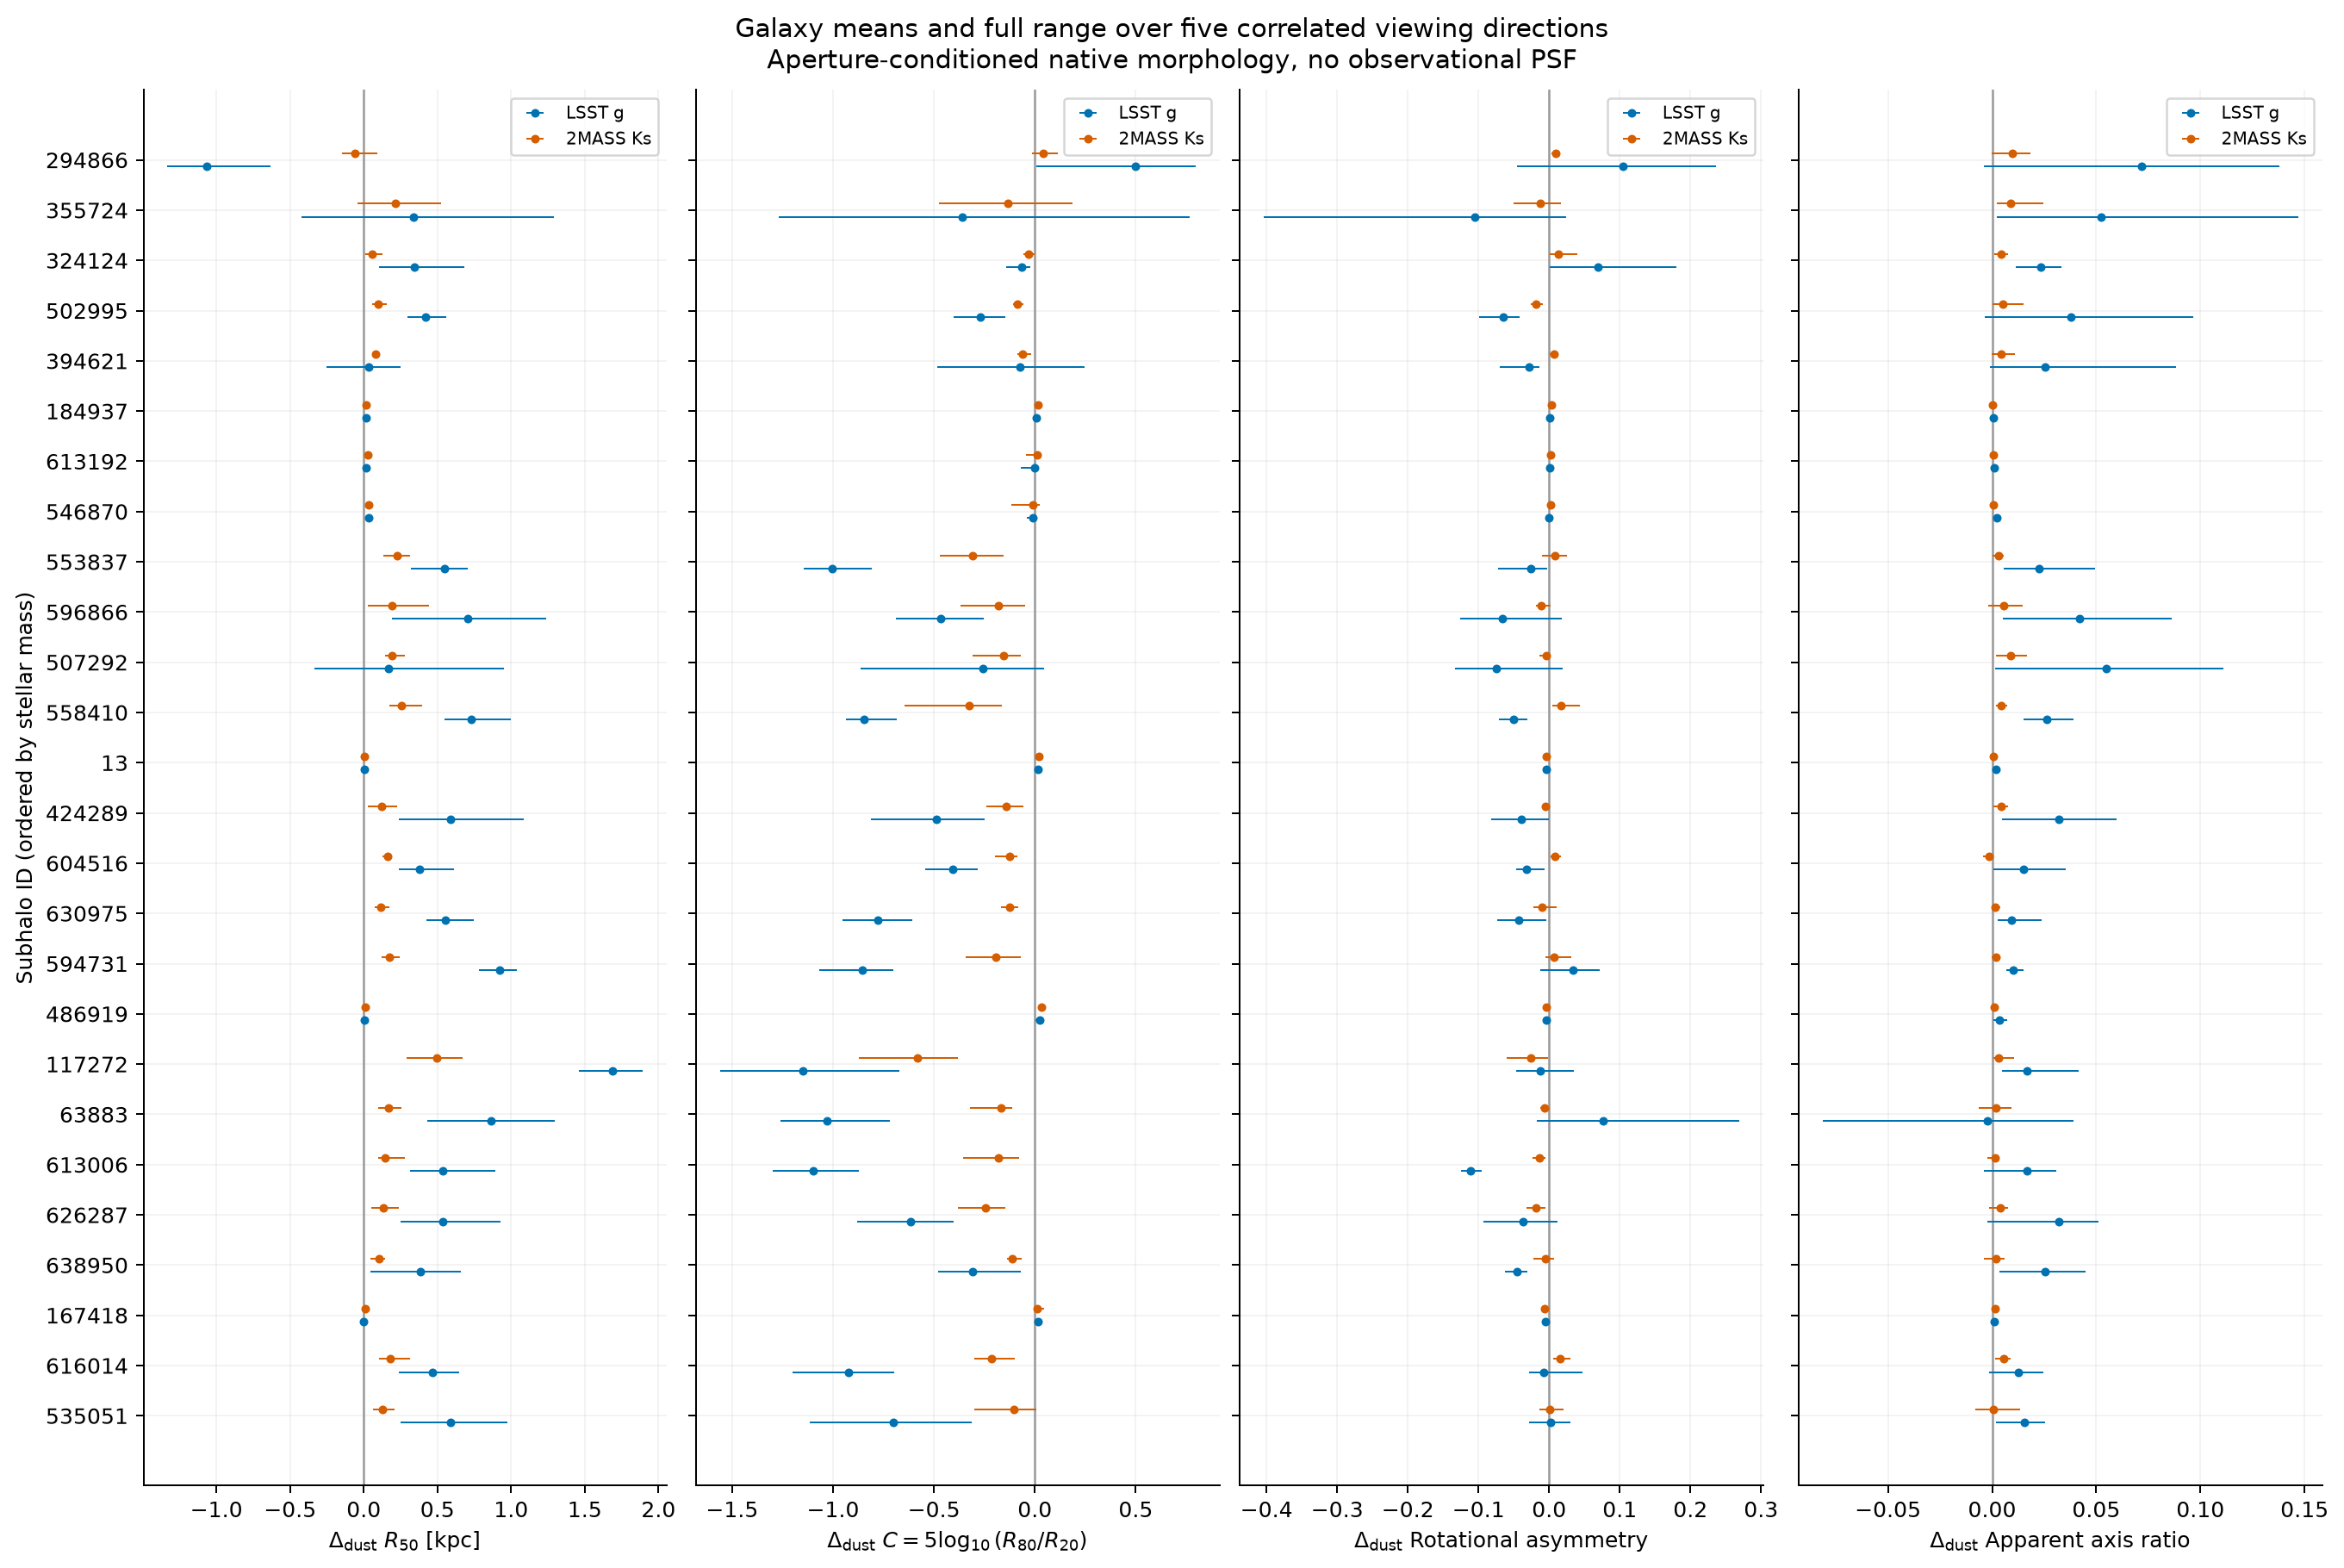

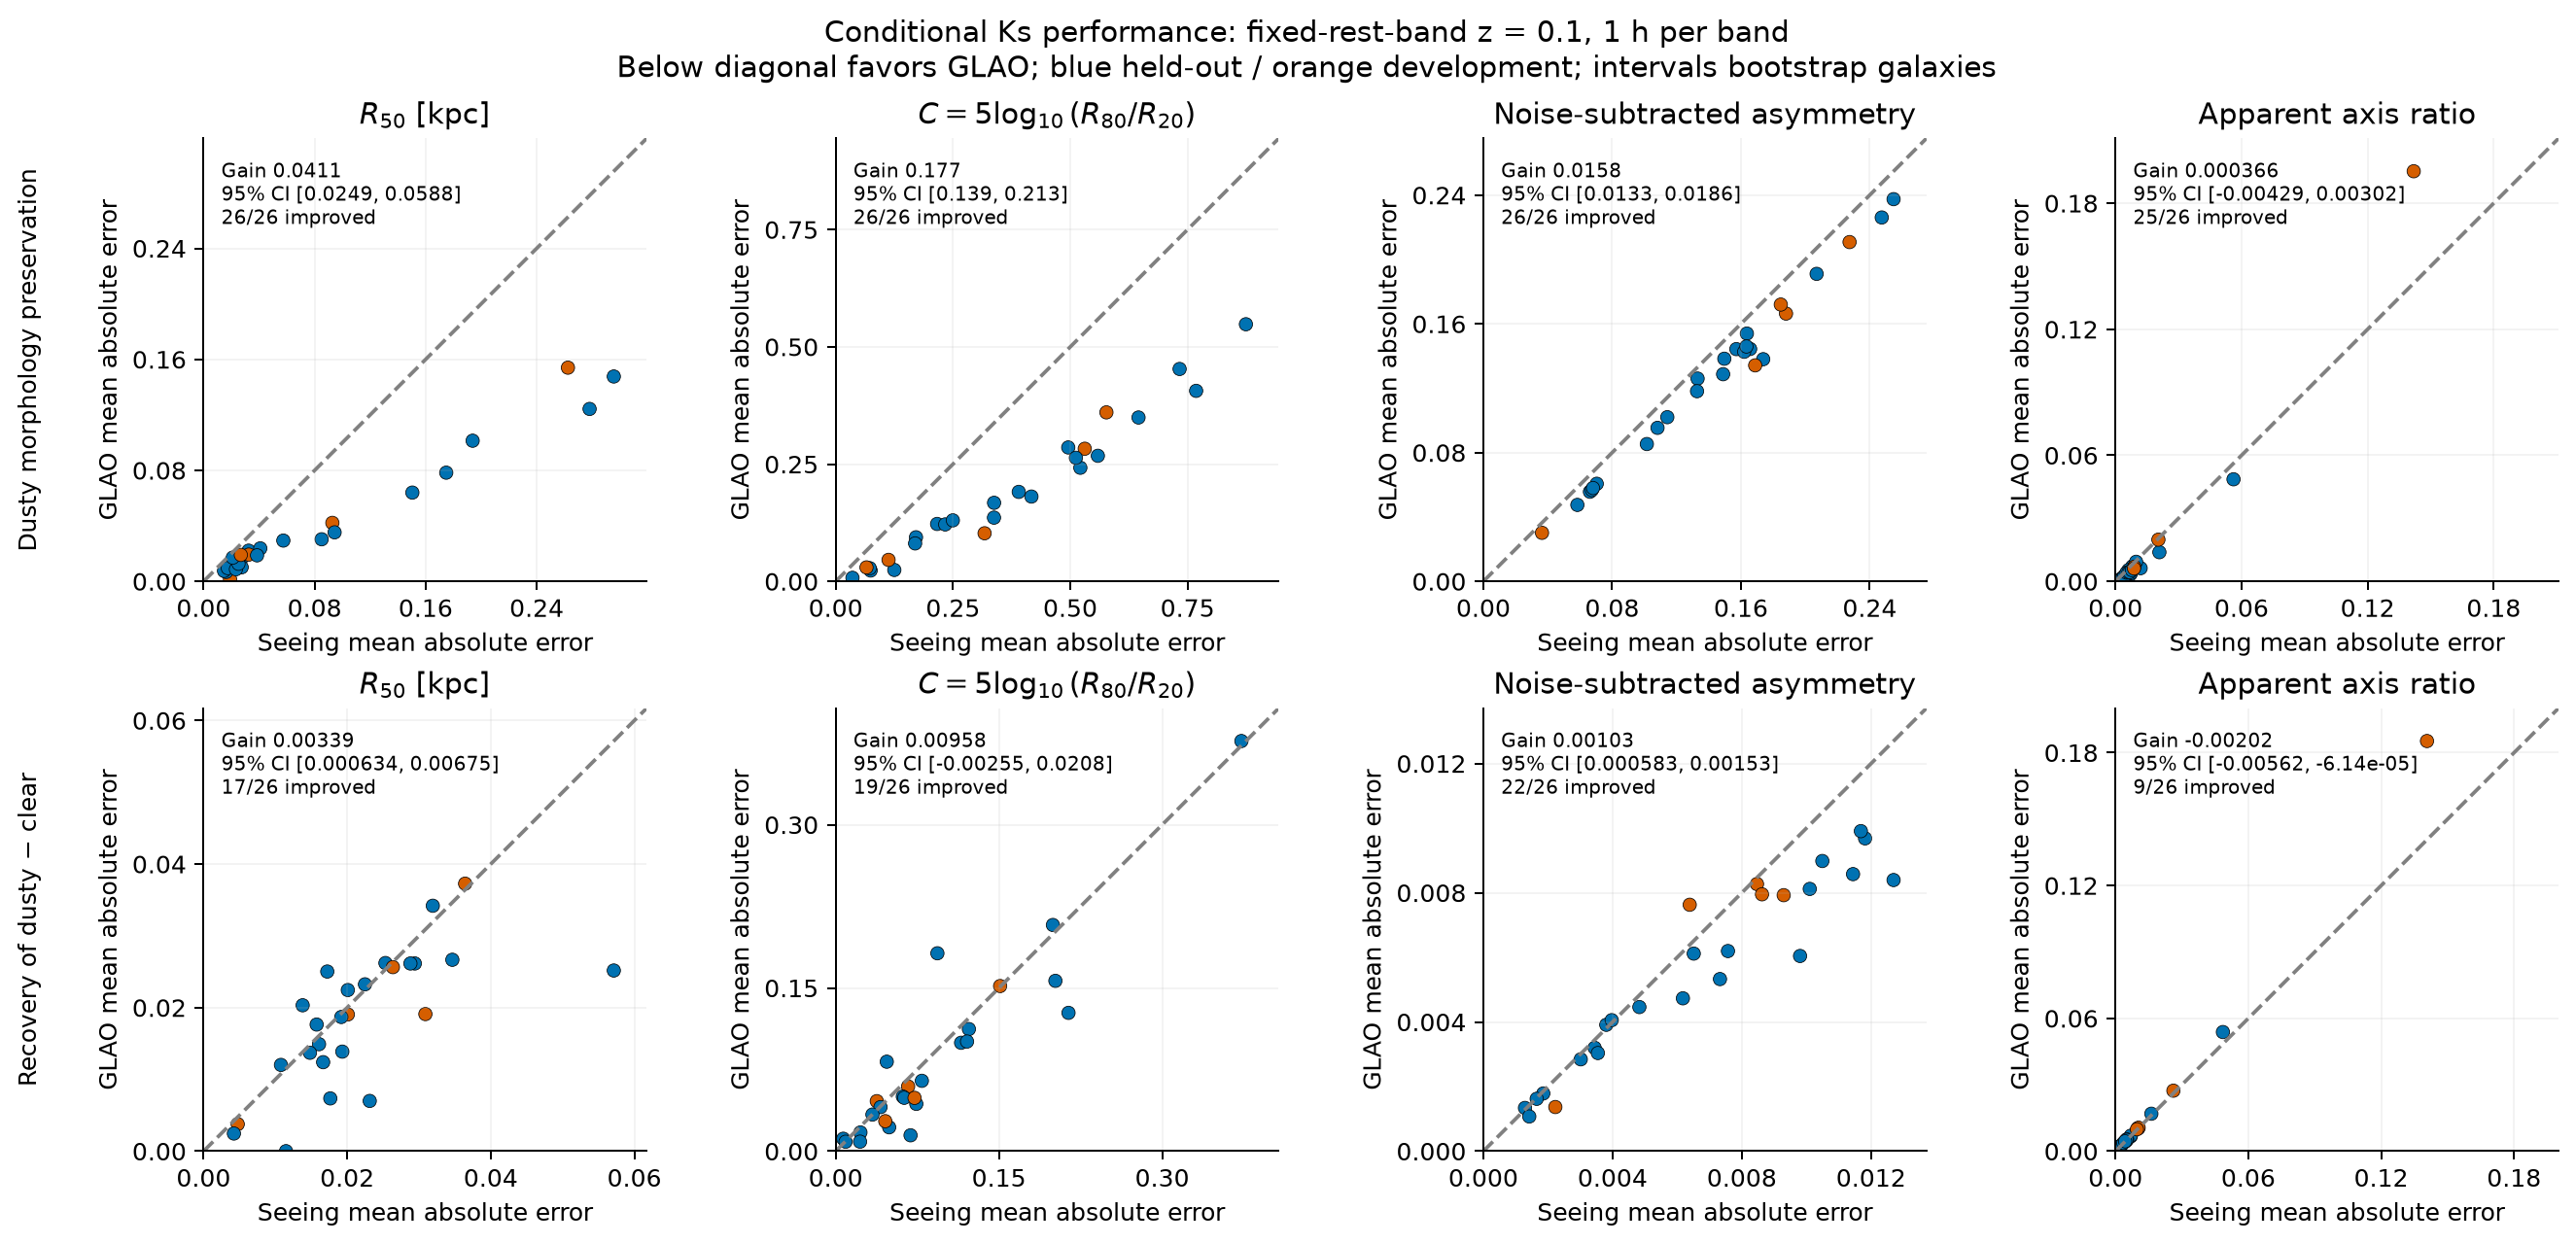

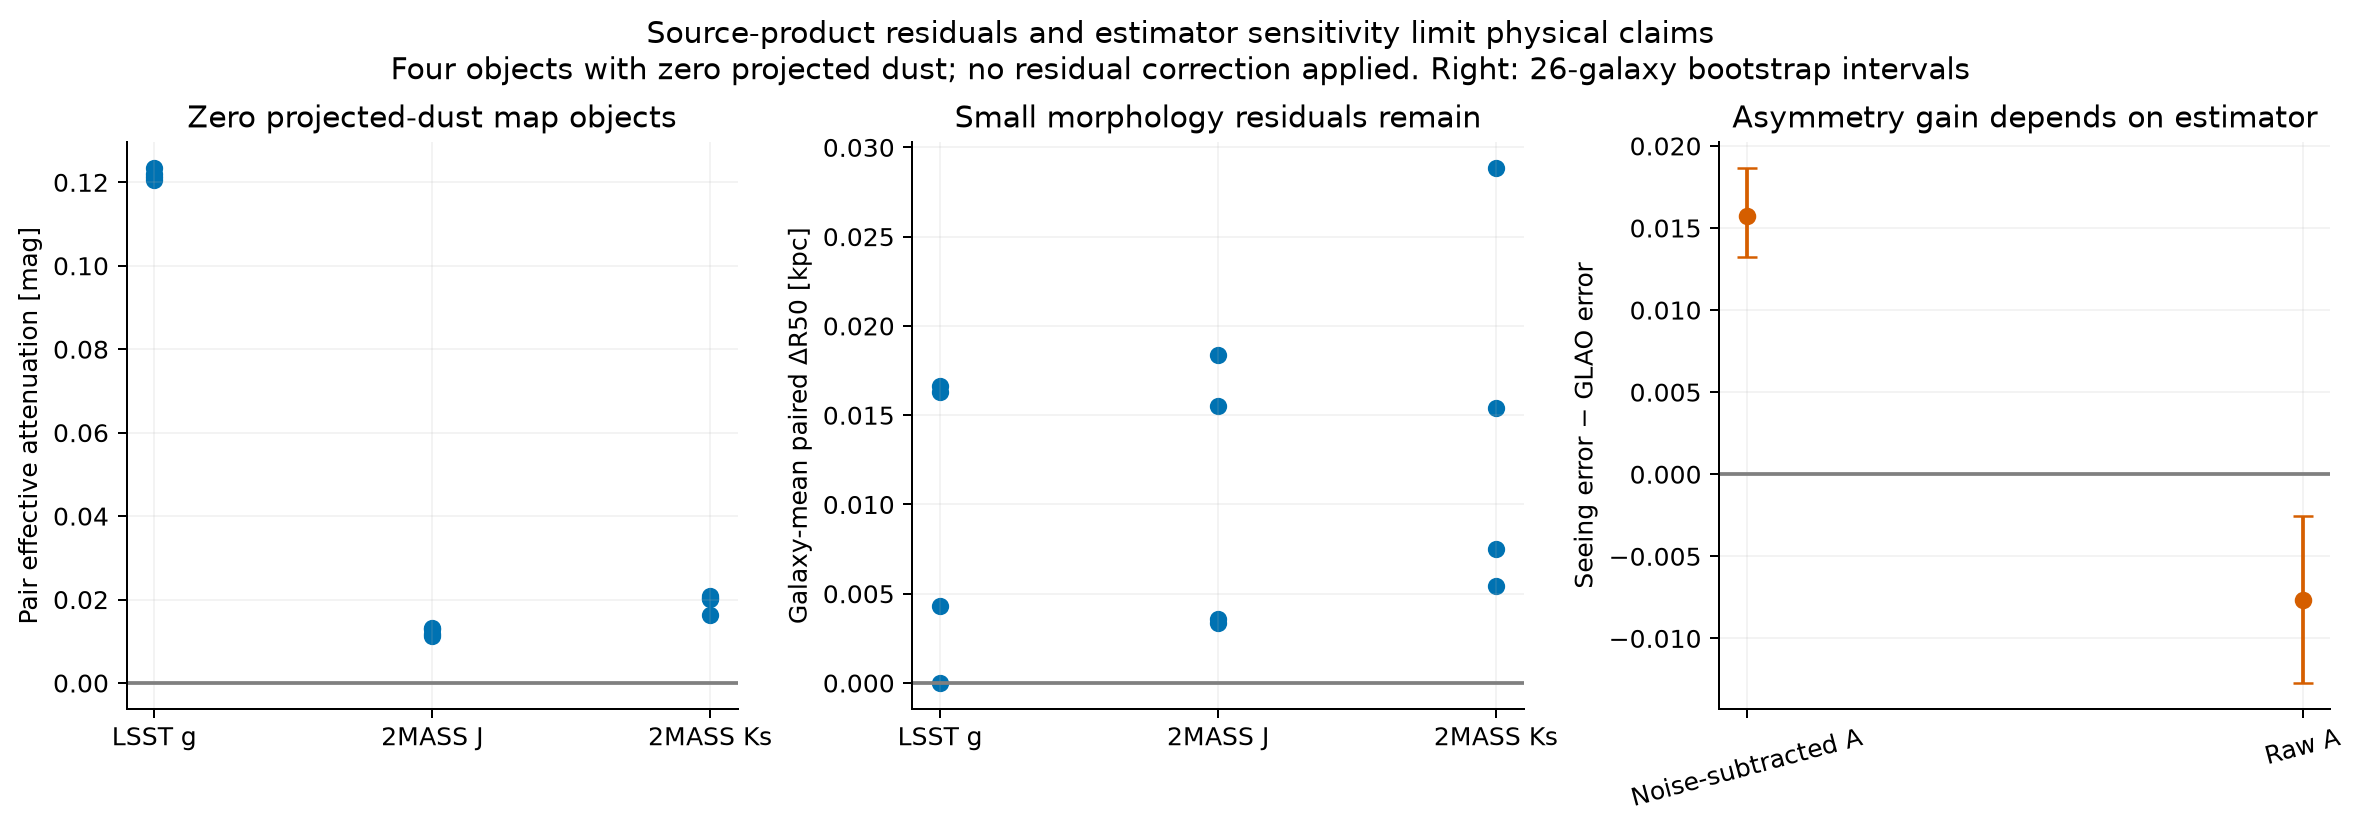

In [4]:
for name in ['03_per_galaxy_bias.png', '05_GLAO_morphology_accuracy.png', '11_source_and_estimator_controls.png']:
    display(Image(filename=str(STUDY/'figures'/name)))

## Interpretation

The numerical reproduction and primary-study provenance can be verified independently. Four zero-projected-dust objects still show nonzero image-pair residuals; no offset is subtracted. Physical attribution of the smallest contrasts remains unresolved. Aperture sensitivity, nonrepresentative selection, eight science noise draws and provisional PSFs limit generalization. See the primary scientific report and this directory’s README for exact results and reproduction commands.